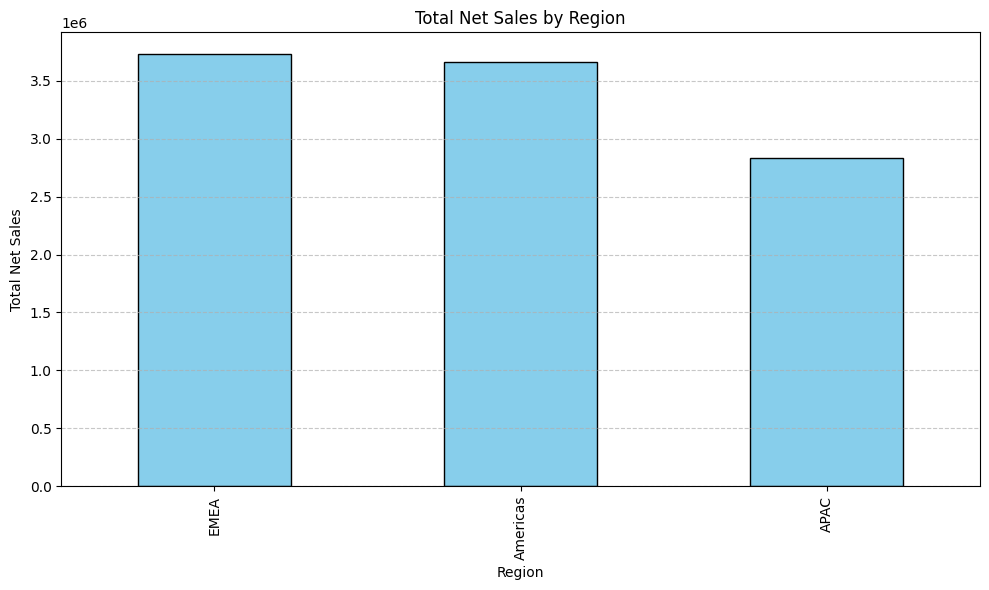

Insight: The 'EMEA' region has the highest total net sales, while the 'APAC' region has the lowest.



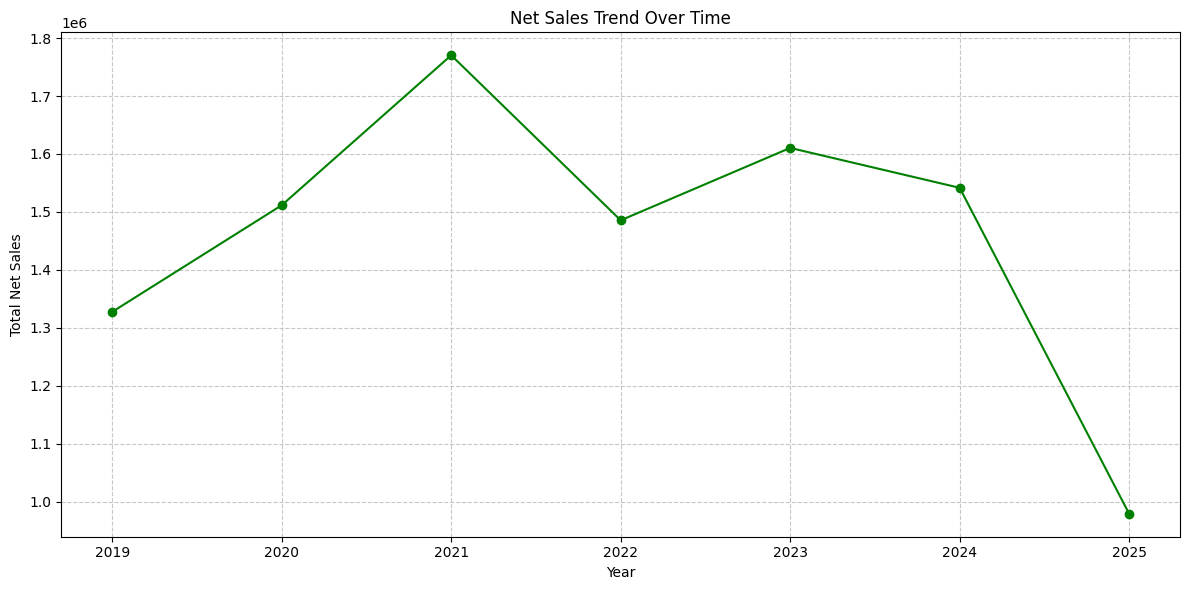

Insight: Net sales increased overall and reached the highest point in 2021.



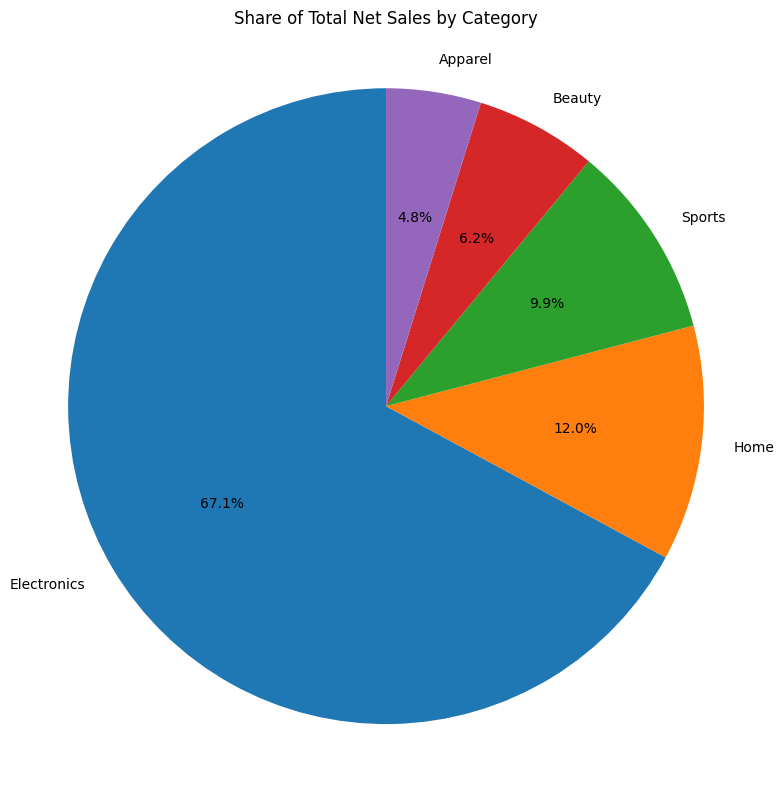

Insight: The 'Electronics' category has the largest share of total net sales.



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('sales.csv')
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['net_sales'] = pd.to_numeric(df['net_sales'], errors='coerce')
df['gross_sales'] = pd.to_numeric(df.get('gross_sales', df['net_sales']), errors='coerce')

def select_chart_type(x_type, y_type):
    if x_type == 'temporal' and y_type == 'quantitative':
        return 'line'
    elif x_type == 'categorical' and y_type == 'quantitative':
        return 'bar'
    elif x_type == 'categorical' and y_type == 'proportional':
        return 'pie'
    elif x_type == 'quantitative' and y_type == 'quantitative':
        return 'scatter'
    else:
        return 'bar'


x_type, y_type = 'categorical', 'quantitative'
chart_type = select_chart_type(x_type, y_type)
region_sales = df.groupby('region')['net_sales'].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
if chart_type == 'bar':
    region_sales.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Total Net Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Net Sales")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
print(f"Insight: The '{region_sales.idxmax()}' region has the highest total net sales, while the '{region_sales.idxmin()}' region has the lowest.\n")


x_type, y_type = 'temporal', 'quantitative'
chart_type = select_chart_type(x_type, y_type)
if 'year' not in df.columns:
    df['year'] = df['date'].dt.year
annual_sales = df.groupby('year')['net_sales'].sum().sort_index()
plt.figure(figsize=(12, 6))
if chart_type == 'line':
    plt.plot(annual_sales.index, annual_sales.values, marker='o', color='green')
plt.title("Net Sales Trend Over Time")
plt.xlabel("Year")
plt.ylabel("Total Net Sales")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
print(f"Insight: Net sales increased overall and reached the highest point in {annual_sales.idxmax()}.\n")


x_type, y_type = 'categorical', 'proportional'
chart_type = select_chart_type(x_type, y_type)
category_sales = df.groupby('category')['net_sales'].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 8))
if chart_type == 'pie':
    plt.pie(category_sales, labels=category_sales.index, autopct='%1.1f%%', startangle=90)
plt.title("Share of Total Net Sales by Category")
plt.axis('equal')
plt.tight_layout()
plt.show()
print(f"Insight: The '{category_sales.idxmax()}' category has the largest share of total net sales.\n")
